# 4. Reading the results and choosing a model

This notebook opens the Boston backtest saved by notebook 1. If notebook 1 hasn't been run, it runs a small backtest first.

It answers four questions:

1. Which model was best, and was it clearly better than persistence?
2. Are the uncertainty bands honest?
3. Where in the season did the models do well or badly?
4. Which forecast should a department actually use?

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import areafluforecast as af

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110
import numpy as np
from areafluforecast.intervals import QUANTILE_COLUMNS
from areafluforecast.scoring import add_cell_scores, pit_values

In [2]:
city = af.load_sample("boston")
bt = af.latest_backtest(city, out_dir="runs")
if bt is None:
    SMALL = {"gnn_st": {"n_seeds": 2}, "lstm": {"n_seeds": 2}, "colagnn": {"n_seeds": 2}}
    bt = af.backtest(city, seasons=1, horizons=(1, 2), configs=SMALL, out_dir="runs")
print("backtest:", bt.path, "| seasons:", bt.meta["season_labels"])

backtest: runs/boston/backtest_20261004-234917 | seasons: ['2024-25']


## 1. Who beat persistence?

This bar chart shows relative WIS: the model's error over persistence's, on the same weeks. A bar left of the line beat "next week looks like this week".

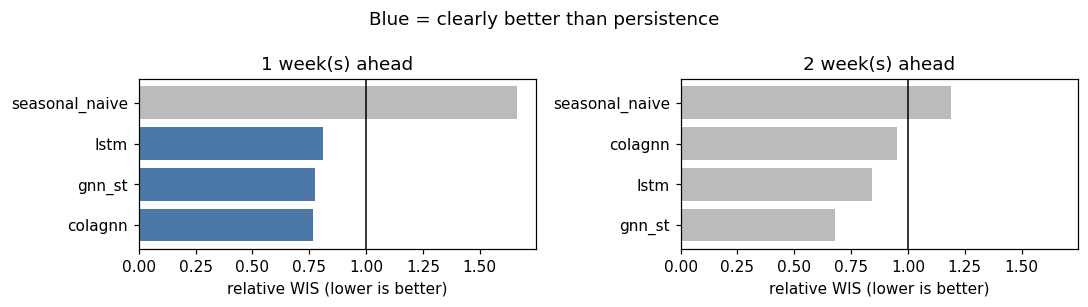

In [3]:
comp = bt.comparison.copy()
fig, axes = plt.subplots(1, comp.horizon.nunique(), figsize=(10, 2.8), sharex=True)
for ax, (h, part) in zip(np.atleast_1d(axes), comp.groupby("horizon")):
    part = part.sort_values("relative_wis")
    colors = ["#4C78A8" if v == "better than persistence" else "#BBBBBB" for v in part.verdict]
    ax.barh(part.model, part.relative_wis, color=colors)
    ax.axvline(1, color="black", lw=1)
    ax.set_title(f"{h} week(s) ahead"); ax.set_xlabel("relative WIS (lower is better)")
fig.suptitle("Blue = clearly better than persistence"); fig.tight_layout()

In [4]:
comp[["horizon", "model", "relative_wis", "p_holm", "verdict"]].sort_values(["horizon", "relative_wis"]).round(3)

,horizon,model,relative_wis,p_holm,verdict
0,1,colagnn,0.765,0.001,better than persistence
1,1,gnn_st,0.777,0.000,better than persistence
2,1,lstm,0.812,0.047,better than persistence
3,1,seasonal_naive,1.665,0.002,worse than persistence
5,2,gnn_st,0.677,0.055,not clearly better than persistence
6,2,lstm,0.842,0.742,not clearly better than persistence
4,2,colagnn,0.950,0.768,not clearly better than persistence
7,2,seasonal_naive,1.187,0.742,no better than persistence


## 2. Are the bands honest?

A 95% band should contain the truth about 95% of the time. Much lower means the model is overconfident, and much higher means its bands are wider than they need to be.

In [5]:
(bt.scores.groupby(["horizon", "model"])["coverage95"].mean().unstack(0) * 100).round(1)

horizon,1,2
model,,
colagnn,93.6,86.0
gnn_st,93.1,90.7
lstm,94.1,88.8
persistence,93.1,89.1
seasonal_naive,97.0,97.0


A finer check is the **PIT histogram**. For each observed week it asks where the truth fell within the forecast's distribution. If the forecast is calibrated, the bars are flat. A U shape means the bands are too narrow, and a hump means they're too wide.

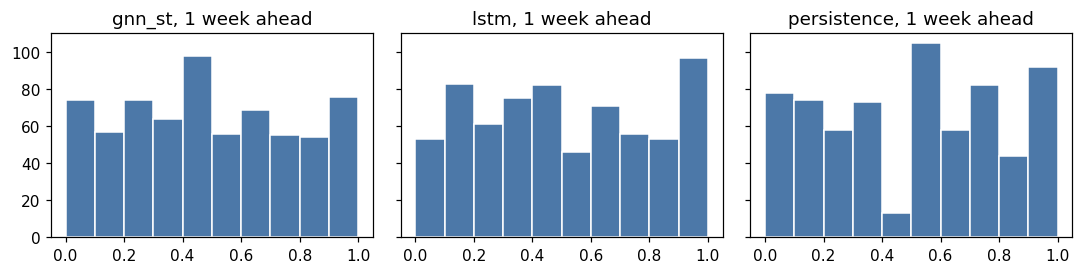

In [6]:
pred = bt.predictions.dropna(subset=["actual"])
models = [m for m in ["gnn_st", "lstm", "persistence"] if m in set(pred.model)]
fig, axes = plt.subplots(1, len(models), figsize=(10, 2.6), sharey=True)
for ax, m in zip(axes, models):
    part = pred[(pred.model == m) & (pred.horizon == 1)]
    ax.hist(pit_values(part.actual, part[list(QUANTILE_COLUMNS)].to_numpy()), bins=10,
            range=(0, 1), color="#4C78A8", edgecolor="white")
    ax.set_title(f"{m}, 1 week ahead")
fig.tight_layout()

## 3. Where in the season?

Errors are rarely spread evenly. Most of the WIS usually comes from the weeks around the peak.

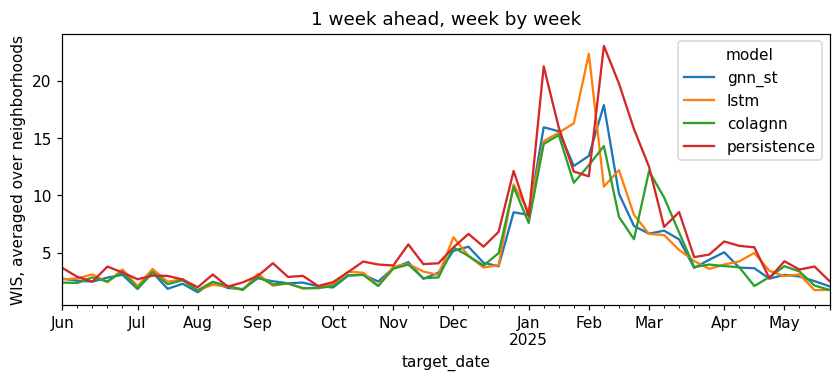

In [7]:
scored = add_cell_scores(pred)
weekly = scored[scored.horizon == 1].groupby(["target_date", "model"]).wis.mean().unstack()
ax = weekly[[m for m in ["gnn_st", "lstm", "colagnn", "persistence"] if m in weekly]]\
    .plot(figsize=(9, 3.2))
ax.set_ylabel("WIS, averaged over neighborhoods"); ax.set_title("1 week ahead, week by week");

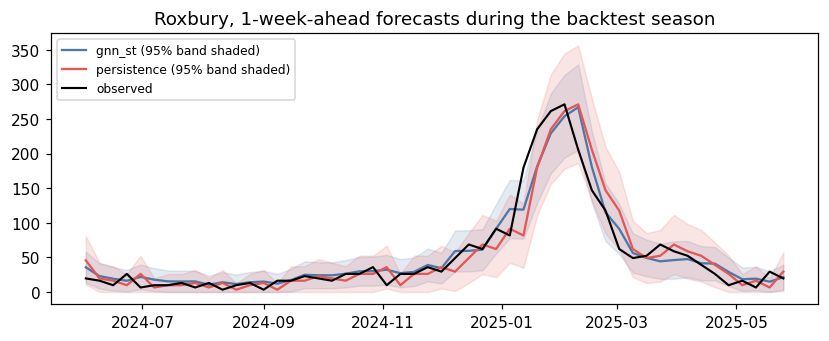

In [8]:
area = "Roxbury"
fig, ax = plt.subplots(figsize=(9, 3.2))
for m, color in [("gnn_st", "#4C78A8"), ("persistence", "#E45756")]:
    part = pred[(pred.model == m) & (pred.horizon == 1) & (pred.area == area)].sort_values("target_date")
    ax.fill_between(part.target_date, part.lower, part.upper, color=color, alpha=0.15)
    ax.plot(part.target_date, part.predicted, color=color, label=f"{m} (95% band shaded)")
ax.plot(part.target_date, part.actual, color="black", lw=1.4, label="observed")
ax.legend(fontsize=8); ax.set_title(f"{area}, 1-week-ahead forecasts during the backtest season");

## 3b. Is the forecast late?

The timing diagnostic slides each model's forecasts earlier, one week at a time, and reports the slide that fits best. Persistence is exactly *h* weeks behind by construction. A model that matches it got its advantage from the size of the curve, not from earlier turns.

In [9]:
from areafluforecast.timing import describe, timing_table
timing = bt.timing if not bt.timing.empty else timing_table(bt.predictions)
for _, row in timing.sort_values(["horizon", "model"]).iterrows():
    print(describe(row))

colagnn, 1 wk ahead: 1 week(s) behind the curve (no earlier than persistence); 48% of its squared error is timing; peaks a median 1 week(s) late
gnn_st, 1 wk ahead: 1 week(s) behind the curve (no earlier than persistence); 67% of its squared error is timing; peaks a median 1 week(s) late
lstm, 1 wk ahead: 1 week(s) behind the curve (no earlier than persistence); 28% of its squared error is timing; peaks a median 1 week(s) late
persistence, 1 wk ahead: 1 week(s) behind the curve (exactly 1 by construction)
seasonal_naive, 1 wk ahead: does not follow the recent curve (it copies an earlier season), so 'weeks behind' does not apply; its peak is a median -5.5 week(s) off
colagnn, 2 wk ahead: 2 week(s) behind the curve (no earlier than persistence); 47% of its squared error is timing; peaks a median 2 week(s) late
gnn_st, 2 wk ahead: 2 week(s) behind the curve (no earlier than persistence); 36% of its squared error is timing; peaks a median 2 week(s) late
lstm, 2 wk ahead: 2 week(s) behind t

## 4. Which forecast should we use?

A simple, defensible rule: for each horizon, use the model with the lowest WIS among those **clearly better than persistence**. If none is clearly better, report persistence, or report the forecasts with a caveat. The backtest is evidence about your city, and "none of the models helped" is a legitimate finding.

In [10]:
def choose(comparison):
    rows = []
    for h, part in comparison.groupby("horizon"):
        good = part[part.verdict == "better than persistence"]
        best = good.nsmallest(1, "wis")
        rows.append({"horizon": h,
                     "use": best.model.iloc[0] if len(best) else "persistence",
                     "relative_wis": round(float(best.relative_wis.iloc[0]), 3) if len(best) else 1.0})
    return pd.DataFrame(rows)

choose(bt.comparison)

,horizon,use,relative_wis
0,1,colagnn,0.765
1,2,persistence,1.000


**Caveats to state with any forecast:**

- **One season is one season.** Backtest two or more before relying on a model.
- **Reporting delays aren't simulated.** If your data arrives late, a "1-week" forecast is really further ahead.
- **Tuning matters.** `tune=True` picks each model's settings from 12 candidates, using only weeks before the season. It's how the paper compared models fairly, and it costs about 12× the time.